# ETL: toxic messages REST API → Postgres + Kafka

## Описание
* **Источник** — `dataset-api` (REST API в docker), который отдаёт постранично локальный дамп `data/dump_features_include_numeric_1.csv` (или `data/sample_dump_features.csv`, если полного дампа нет).
* **Extract** — пагинация `GET /messages?offset=&limit=`.
* **Transform** — приведение к целевой схеме (по мотивам `get_raw_data_and_merge.ipynb`): типы, мусорные/пустые тексты, дубли, метки `is_toxic`, простая валидация без great expectations.
* **Load** — `toxicity.messages` в Postgres (`ON CONFLICT DO NOTHING`) + только *новые* строки в Kafka-топик `api-source` => повторный запуск не создаёт дублей нигде.
* Новые строки также публикуются в Kafka-топик `api-source` (смотреть в kafka-ui).

## Импорты

In [1]:
import os
import sys
import time
import logging
from pathlib import Path

import requests
import numpy as np
import pandas as pd
import psycopg2
import matplotlib.pyplot as plt
from psycopg2.extras import execute_values
from dotenv import load_dotenv

## Конфигурация

In [2]:
# repo root (notebook can be run from notebooks/ or from the root):
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
SRC = ROOT / 'src'

if not load_dotenv(ROOT / '.env'):
    raise FileNotFoundError(f'{ROOT / ".env"} not found, run: cp .env.example .env')

# source api:
API_URL = os.getenv('API_URL', 'http://localhost:8001')
PAGE_SIZE = int(os.getenv('PAGE_SIZE', 5000))
MAX_ROWS = int(os.getenv('MAX_ROWS', 20000))  # 0 = all rows

# kafka:
KAFKA_BOOTSTRAP = os.getenv('KAFKA_BOOTSTRAP', 'localhost:9092')
KAFKA_TOPIC = os.getenv('KAFKA_TOPIC', 'api-source')

# target db, passwords from .env only:
PG_PARAMS = dict(
    host=os.getenv('PG_HOST', 'localhost'),
    port=int(os.getenv('PG_PORT', 5432)),
    dbname=os.getenv('POSTGRES_DB'),
    user=os.getenv('POSTGRES_USER'),
    password=os.getenv('POSTGRES_PASSWORD'),
)
missing = [k for k, v in PG_PARAMS.items() if v is None]
if missing:
    raise ValueError(f'Missing postgres params in .env: {missing}')

# logging:
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s', force=True)
logger = logging.getLogger('etl')
# kafka-python is too talkative on INFO: 
logging.getLogger('kafka').setLevel(logging.WARNING)

print(f'API_URL={API_URL}, PAGE_SIZE={PAGE_SIZE}, MAX_ROWS={MAX_ROWS}, '
      f'KAFKA={KAFKA_BOOTSTRAP}/{KAFKA_TOPIC}, PG={PG_PARAMS["host"]}:{PG_PARAMS["port"]}/{PG_PARAMS["dbname"]}')

API_URL=http://dataset-api:8001, PAGE_SIZE=5000, MAX_ROWS=20000, KAFKA=kafka:29092/api-source, PG=postgres:5432/toxicity


## Extract

In [3]:
def get_page(offset: int, limit: int, retries: int = 3) -> dict:
    """One page of the dataset api with retries and exponential backoff"""

    for attempt in range(1, retries + 1):
        try:
            resp = requests.get(f'{API_URL}/messages', params={'offset': offset, 'limit': limit}, timeout=60)
            resp.raise_for_status()
            return resp.json()
        except requests.RequestException as e:
            logger.warning(f'GET /messages offset={offset} attempt {attempt}/{retries} failed: {e}')
            if attempt == retries:
                raise
            time.sleep(2 ** (attempt - 1))


def extract_all(max_rows: int = 0) -> pd.DataFrame:
    """Paginate over the api until max_rows (0 = everything)"""

    items, offset = [], 0
    while True:
        limit = PAGE_SIZE if not max_rows else min(PAGE_SIZE, max_rows - offset)
        if limit <= 0:
            break

        page = get_page(offset, limit)
        if not page['items']:
            break

        items.extend(page['items'])
        offset += len(page['items'])
        logger.info(f'Extracted {offset} rows (api total: {page["total"]})')

        if offset >= page['total']:
            break

    return pd.DataFrame(items)


# check that the api is alive before the extraction:
try:
    health = requests.get(f'{API_URL}/health', timeout=10).json()
    logger.info(f'dataset-api is ok: {health}')
    df_raw = extract_all(MAX_ROWS)
except requests.RequestException as e:
    raise RuntimeError(f'Dataset API is not available at {API_URL} ({e}). Was `docker compose up -d` done?') from e

print(df_raw.shape)
df_raw.head(3)

2026-11-24 13:39:58,317 - INFO - dataset-api is ok: {'status': 'ok', 'rows': 5000}


2026-11-24 13:39:58,656 - INFO - Extracted 5000 rows (api total: 5000)


(5000, 19)


,raw_text_id,dataset_id,source_platform,is_verified,text_raw,is_toxic,toxicity_type,count_spp,count_rpp,count_profanity,has_emoji,has_emoticon,has_capslock,is_all_lower,is_bad_word_incl,has_url,has_number,has_mention,has_hashtag
0,0,0,"2ch, pikabu",1,"Верблюдов-то за что? Дебилы, бл...\n",1.0,None,3,1,0,0,0,1,0,0,0,0,0,0
1,96,0,"2ch, pikabu",1,Э че бля а? Ты че нах бл иди сюда епты.. Ты за...,1.0,None,2,1,3,0,0,1,0,1,0,0,0,0
2,192,0,"2ch, pikabu",1,Религиозным можно быть по-разному. Я не говорю...,1.0,None,10,0,0,0,0,1,0,0,0,0,0,0


## Transform

In [4]:
# target data schema (= toxicity.messages in init/init.sql):
TARGET_SCHEMA = {
    'raw_text_id': 'int64',
    'dataset_id': 'int16',
    'source_platform': 'string',  # name of the site/forum/etc
    'is_verified': 'boolean',     # is source data was manually/automatically verified
    'text_raw': 'string',         # raw text column
    'is_toxic': 'Int8',           # binary target column, <NA> = unlabelled
    'toxicity_type': 'string',    # multilabel target column
    'text_length': 'Int32',
}
COUNT_COLS = ['count_spp', 'count_rpp', 'count_profanity']
FLAG_COLS = ['has_emoji', 'has_emoticon', 'has_capslock', 'is_all_lower',
             'is_bad_word_incl', 'has_url', 'has_number', 'has_mention', 'has_hashtag']
TARGET_SCHEMA.update({c: 'Int32' for c in COUNT_COLS})
TARGET_SCHEMA.update({c: 'boolean' for c in FLAG_COLS})


def transform(df_raw: pd.DataFrame) -> pd.DataFrame:
    df = df_raw.copy()

    # empty / whitespace-only texts are garbage (the same as in merge notebook):
    df['text_raw'] = df['text_raw'].astype('string')
    df = df[df['text_raw'].notna() & ~df['text_raw'].str.match(r'^\s*$', na=False)]

    # duplicates by text and by id:
    df = df.drop_duplicates(subset='text_raw', keep='first')
    df = df.drop_duplicates(subset='raw_text_id', keep='first')

    # is_toxic: only 0/1, everything else is unknown:
    df['is_toxic'] = df['is_toxic'].where(df['is_toxic'].isin([0, 1]))
    df['toxicity_type'] = df['toxicity_type'].fillna('')

    # simple derived feature:
    df['text_length'] = df['text_raw'].str.len()

    # flags are 0/1 numbers in the dump => float first to keep NaN:
    for c in FLAG_COLS + ['is_verified']:
        df[c] = df[c].astype('float').astype('boolean')

    return df.astype(TARGET_SCHEMA)[list(TARGET_SCHEMA)]


def validate_df_batch(df: pd.DataFrame) -> pd.DataFrame:
    """Expectations from the merge notebook, but on plain pandas (no great expectations)"""

    checks = {
        'expect_columns_to_exist': all(c in df.columns for c in TARGET_SCHEMA),
        'expect_text_raw_not_null': df['text_raw'].notna().all(),
        'expect_text_raw_unique': df['text_raw'].is_unique,
        'expect_raw_text_id_unique': df['raw_text_id'].is_unique,
        'expect_text_raw_not_blank': not df['text_raw'].str.match(r'^\s*$').any(),
        'expect_is_toxic_in_set': df['is_toxic'].dropna().isin([0, 1]).all(),
    }
    return pd.DataFrame({'expectation': checks.keys(), 'success': checks.values()})


df = transform(df_raw)
validation = validate_df_batch(df)
display(validation)
if not validation['success'].all():
    raise ValueError('Batch is incorrect! See failed expectations above')

print(f'raw: {len(df_raw)} -> clean: {len(df)} (dropped {len(df_raw) - len(df)})')
df.dtypes

,expectation,success
0,expect_columns_to_exist,True
1,expect_text_raw_not_null,True
2,expect_text_raw_unique,True
3,expect_raw_text_id_unique,True
4,expect_text_raw_not_blank,True
5,expect_is_toxic_in_set,True


raw: 5000 -> clean: 5000 (dropped 0)


raw_text_id                  int64
dataset_id                   int16
source_platform     string[python]
is_verified                boolean
text_raw            string[python]
is_toxic                      Int8
toxicity_type       string[python]
text_length                  Int32
count_spp                    Int32
count_rpp                    Int32
count_profanity              Int32
has_emoji                  boolean
has_emoticon               boolean
has_capslock               boolean
is_all_lower               boolean
is_bad_word_incl           boolean
has_url                    boolean
has_number                 boolean
has_mention                boolean
has_hashtag                boolean
dtype: object

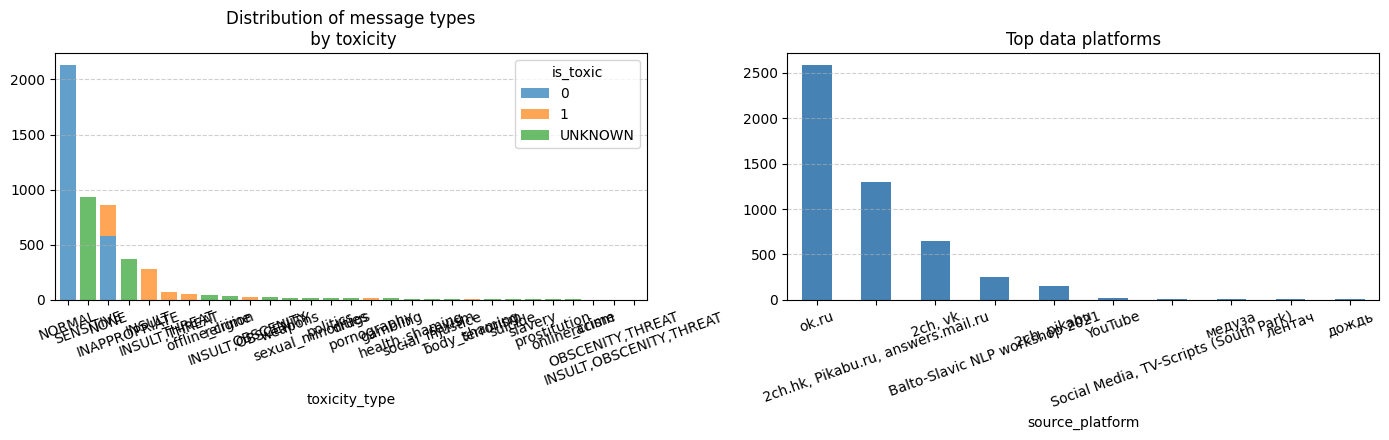

is_toxic median: 0.0 | toxic share: 0.214


In [5]:
# quick look at the data (plots from the merge notebook):
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

df_plot = df.copy()
df_plot['is_toxic'] = df_plot['is_toxic'].astype('string').fillna('UNKNOWN')
df_plot['toxicity_type'] = df_plot['toxicity_type'].replace('', 'NONE')
toxicity_counts = df_plot.groupby(['toxicity_type', 'is_toxic']).size().unstack(fill_value=0)
toxicity_counts = toxicity_counts.loc[toxicity_counts.sum(axis=1).sort_values(ascending=False).index]
toxicity_counts.plot(kind='bar', stacked=True, ax=axes[0], width=0.8, alpha=0.7)
axes[0].set_title('Distribution of message types\n by toxicity')
axes[0].tick_params(axis='x', rotation=20)

df['source_platform'].value_counts().head(10).plot(kind='bar', ax=axes[1], color='steelblue')
axes[1].set_title('Top data platforms')
axes[1].tick_params(axis='x', rotation=20)

for ax in axes:
    ax.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# label balance of the loaded slice:
print('is_toxic median:', df['is_toxic'].dropna().median(), '| toxic share:', round(df['is_toxic'].dropna().mean(), 3))

## Load

In [6]:
def to_records(df: pd.DataFrame) -> list:
    """pandas NA / numpy types -> python values for psycopg2"""
    return [
        tuple(None if pd.isna(v) else (v.item() if hasattr(v, 'item') else v) for v in row)
        for row in df.itertuples(index=False, name=None)
    ]


def load_to_postgres(df: pd.DataFrame) -> list:
    """Idempotent insert, returns ids of really inserted rows"""

    cols = list(TARGET_SCHEMA)
    query = f"""
        INSERT INTO toxicity.messages ({', '.join(cols)}) VALUES %s
        ON CONFLICT (raw_text_id) DO NOTHING
        RETURNING raw_text_id
    """
    try:
        conn = psycopg2.connect(**PG_PARAMS)
    except psycopg2.OperationalError as e:
        raise RuntimeError(f'Postgres is not available at {PG_PARAMS["host"]}:{PG_PARAMS["port"]}: {e}') from e

    try:
        with conn, conn.cursor() as cur:
            inserted = execute_values(cur, query, to_records(df), page_size=1000, fetch=True)
    except psycopg2.Error as e:
        raise RuntimeError(f'Insert into toxicity.messages failed: {e}') from e
    finally:
        conn.close()

    return [r[0] for r in inserted]


inserted_ids = load_to_postgres(df)
logger.info(f'Postgres: {len(inserted_ids)} new rows, {len(df) - len(inserted_ids)} already existed')

2026-11-24 13:39:59,476 - INFO - Postgres: 5000 new rows, 0 already existed


In [7]:
# kafka: only new rows => no duplicates in the topic after rerun.
# producer is reused from src/message_producers/producer.py:
sys.path[:0] = [str(SRC), str(SRC / 'message_producers')]
os.environ['KAFKA_BOOTSTRAP'] = KAFKA_BOOTSTRAP
from producer import ToxicityProducer

df_new = df[df['raw_text_id'].isin(inserted_ids)]

if df_new.empty:
    logger.info('Kafka: nothing new to send')
else:
    producer = ToxicityProducer(
        kafka_cfg=str(SRC / 'message_producers' / 'kafka_config.json'),
        source_cfg=str(SRC / 'message_producers' / 'api_producer' / 'source_config.json'),
    )
    if producer.producer is None:
        raise RuntimeError(f'Kafka is not available at {KAFKA_BOOTSTRAP}')

    try:
        for raw_text_id, text in zip(df_new['raw_text_id'], df_new['text_raw']):
            producer.produce_message(text, topic=KAFKA_TOPIC, extra={'raw_text_id': int(raw_text_id)})
        producer.producer.flush()
    finally:
        producer.producer.close()

    logger.info(f'Kafka: {len(df_new)} messages sent to {KAFKA_TOPIC}')

2026-11-24 13:39:59,668 - INFO - Connected to Kafka at kafka:29092


2026-11-24 13:40:00,266 - INFO - Kafka: 5000 messages sent to api-source


## Проверка

In [8]:
def query_df(sql: str) -> pd.DataFrame:
    with psycopg2.connect(**PG_PARAMS) as conn, conn.cursor() as cur:
        cur.execute(sql)
        res = pd.DataFrame(cur.fetchall(), columns=[d[0] for d in cur.description])
    conn.close()
    return res


In [9]:
print(query_df('SELECT COUNT(*) AS cnt FROM toxicity.messages'))
query_df('''
    SELECT raw_text_id, dataset_id, source_platform, is_toxic, toxicity_type,
           left(text_raw, 60) AS text_raw, text_length
    FROM toxicity.messages ORDER BY raw_text_id LIMIT 5
''')

    cnt
0  5000


,raw_text_id,dataset_id,source_platform,is_toxic,toxicity_type,text_raw,text_length
0,0,0,"2ch, pikabu",1,,"Верблюдов-то за что? Дебилы, бл...\n",35
1,96,0,"2ch, pikabu",1,,Э че бля а? Ты че нах бл иди сюда епты.. Ты за...,98
2,192,0,"2ch, pikabu",1,,Религиозным можно быть по-разному. Я не говорю...,305
3,288,0,"2ch, pikabu",0,,"У тебя в домашке мало букв, а мне надо много.\n",46
4,384,0,"2ch, pikabu",1,,"ррряяяяя! Пшла нахуй в свой петушиный загон, в...",63
